# Examen práctico — Q-Learning tabular con Pac-Man

En este ejercicio trabajaremos con una versión pequeña de Pac-Man diseñada para poder resolverse completamente mediante **Q-Learning tabular**.

La lógica es la misma usada previamente:

$$
(S_t,A_t)\rightarrow(R_{t+1},S_{t+1})
$$

y:

$$
Q(S_t,A_t)
\leftarrow
Q(S_t,A_t)
+
\alpha
\left[
R_{t+1}
+
\gamma \max_{a'}Q(S_{t+1},a')
-
Q(S_t,A_t)
\right].
$$

## Objetivo

Implementar un agente Q-Learning capaz de aprender una política que permita a Pac-Man:

- comer tantas comidas como sea posible;
- evitar al fantasma;
- reducir movimientos innecesarios.

> La implementación del ambiente y la visualización ya están disponibles.  
> La tarea consiste en implementar **el agente y su proceso de aprendizaje**.


## 1. Importaciones y ambiente


In [1]:
import sys
from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

PROJECT_ROOT = Path.cwd()
SRC = PROJECT_ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from tabular_pacman_env import (
    TabularPacmanEnv,
    ACTIONS,
)

env = TabularPacmanEnv(seed=7)

print("Número de estados:", env.n_states)
print("Número de acciones:", env.n_actions)


Número de estados: 1944
Número de acciones: 4


## 2. El estado de Pac-Man

Para mantener una Q-table de tamaño manejable utilizaremos la representación:

$$
s=(p,g,n)
$$

donde:

- $p$: posición de Pac-Man;
- $g$: posición del fantasma;
- $n$: número de comidas que permanecen en el tablero.

El ambiente mantiene internamente la posición exacta de cada comida para poder simular y visualizar el juego. Sin embargo, **esa configuración completa no forma parte del estado que recibe la Q-table**.

Por tanto:

$$
n_{\text{states}}
=
n_p\,n_g\,(N_{\text{food}}+1).
$$

Esta es una **representación simplificada del estado**: dos configuraciones distintas de comida pueden compartir el mismo $(p,g,n)$.


Estado codificado: 47
Estado decodificado: PacmanState(pacman=(1, 1), ghost=(2, 5), food_remaining=5)


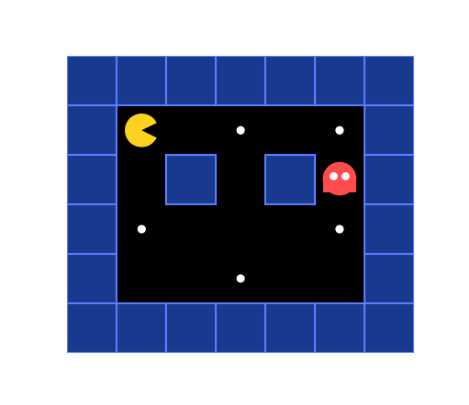

In [2]:
state = env.reset(seed=7)

print("Estado codificado:", state)
print("Estado decodificado:", env.decode_state(state))

frame = env.render()

plt.figure(figsize=(7, 5))
plt.imshow(frame)
plt.axis("off")
plt.show()


### Pregunta 1

Dos tableros pueden tener:

- la misma posición de Pac-Man;
- la misma posición del fantasma;
- el mismo número de comidas restantes;

pero las comidas pueden estar ubicadas en lugares diferentes.

¿Representaría nuestra Q-table ambos tableros como el mismo estado o como estados diferentes? Explique.

**Respuesta.** Los representa como **el mismo estado**. El estado que recibe la Q-table es `s = (p, g, n)`: posición de Pac-Man, posición del fantasma y *cuántas* comidas quedan, no *dónde* están. `encode_state` solo usa `position_to_id[pacman]`, `position_to_id[ghost]` y el entero `food_remaining`, así que dos configuraciones con las mismas `(p, g, n)` producen el mismo `state_id` y comparten la misma fila de Q.

Es una representación simplificada (con *aliasing* de estados): el ambiente sí guarda internamente las posiciones exactas de la comida para simular y dibujar, pero esa información queda fuera del estado del agente. Consecuencia práctica: dos situaciones que en realidad requieren decisiones distintas (p. ej. la comida cercana está a la izquierda vs. a la derecha) se ven idénticas para el agente, lo que introduce algo de ruido/ambigüedad en el aprendizaje. Se acepta para mantener `n_states = n_p · n_g · (N_food + 1)` manejable.


## 3. Acciones


In [3]:
print(ACTIONS)
print("Acciones legales desde el estado inicial:")
print([ACTIONS[a] for a in env.get_legal_actions()])


{0: 'up', 1: 'right', 2: 'down', 3: 'left'}
Acciones legales desde el estado inicial:
['right', 'down']


Las acciones disponibles son:

| Código | Acción |
|---:|---|
| 0 | arriba |
| 1 | derecha |
| 2 | abajo |
| 3 | izquierda |

El ambiente evita atravesar paredes.


## 4. Observar una transición


In [4]:
state = env.reset(seed=7)

action = env.get_legal_actions()[0]

next_state, reward, done, info = env.step(action)

print("S_t       =", state)
print("A_t       =", ACTIONS[action])
print("R_(t+1)   =", reward)
print("S_(t+1)   =", next_state)
print("done      =", done)
print()
print("S_(t+1) decodificado:")
print(env.decode_state(next_state))


S_t       = 47
A_t       = right
R_(t+1)   = -1
S_(t+1)   = 185
done      = False

S_(t+1) decodificado:
PacmanState(pacman=(1, 2), ghost=(3, 5), food_remaining=5)


La transición observada tiene la forma:

$$
(S_t,A_t)\rightarrow(R_{t+1},S_{t+1})
$$

### Pregunta 2

¿Cuáles de los siguientes valores son entregados directamente por el ambiente y cuáles debe aprender/estimar el agente?

- $R_{t+1}$
- $S_{t+1}$
- $Q(S_t,A_t)$
- $\max_{a'}Q(S_{t+1},a')$

**Respuesta.**

| Valor | ¿Quién lo da? |
|---|---|
| $R_{t+1}$ | **Ambiente.** Lo devuelve `env.step(action)` (−1, +10, +30, −30). |
| $S_{t+1}$ | **Ambiente.** También lo devuelve `env.step(action)` (ya codificado como entero). |
| $Q(S_t,A_t)$ | **Agente.** Es una entrada de la Q-table; empieza en 0 y se va estimando con la regla de actualización. |
| $\max_{a'}Q(S_{t+1},a')$ | **Agente.** Se calcula a partir de la Q-table estimada; es la estimación *bootstrap* del valor del estado siguiente. |

En resumen: el ambiente aporta la parte "real" de la experiencia ($R_{t+1}$, $S_{t+1}$); el agente aporta las **estimaciones** ($Q(S_t,A_t)$ y $\max_{a'}Q(S_{t+1},a')$) que se corrigen episodio a episodio.


## 5. Q-table


Construya una Q-table inicializada en cero.

Debe tener dimensiones:

$$
n_{\text{states}}\times n_{\text{actions}}.
$$


In [5]:
# TODO 1 — Inicializar la Q-table
#
# Una fila por estado, una columna por acción, todo en cero.

Q = np.zeros((env.n_states, env.n_actions))


In [6]:
# Esta celda debe ejecutarse cuando TODO 1 esté correcto.

print("Shape esperado:", (env.n_states, env.n_actions))
print("Shape obtenido :", Q.shape)

assert Q.shape == (env.n_states, env.n_actions)
assert np.all(Q == 0)

print("Q-table creada correctamente")


Shape esperado: (1944, 4)
Shape obtenido : (1944, 4)
Q-table creada correctamente


## 6. Política ε-greedy


Implemente:

$$
A_t=
\begin{cases}
\text{acción aleatoria}, & \text{con probabilidad }\epsilon\\[4pt]
\arg\max_a Q(S_t,a), & \text{con probabilidad }1-\epsilon
\end{cases}
$$

Use únicamente las **acciones legales** del estado actual.

Si varias acciones tienen el mismo máximo Q-value, seleccione aleatoriamente entre ellas.


In [7]:
# ============================================================
# TODO 2 — Política epsilon-greedy
# ============================================================

def choose_action(Q, state, epsilon, env):
    legal_actions = env.get_legal_actions()

    # Exploración: acción legal al azar.
    if random.random() < epsilon:
        return random.choice(legal_actions)

    # Explotación: mejor Q entre las acciones legales.
    q_values = [Q[state, a] for a in legal_actions]
    best_value = max(q_values)

    best_actions = [
        a for a, q in zip(legal_actions, q_values)
        if q == best_value
    ]

    # Empate: elegir al azar entre las mejores.
    return random.choice(best_actions)


### Pregunta 3

Si $\epsilon=0.10$:

1. ¿cuál es la probabilidad de explorar?
2. ¿cuál es la probabilidad de explotar?
3. ¿qué ocurre cuando todos los Q-values iniciales son iguales?

**Respuesta.**

1. **Explorar: 0.10** (10 %). Se toma una acción legal al azar con probabilidad $\epsilon$.
2. **Explotar: 0.90** (90 %). Se toma $\arg\max_a Q(S_t,a)$ con probabilidad $1-\epsilon$.
3. Si todos los Q-values son iguales (p. ej. al inicio, todos en 0), el `max` no distingue ninguna acción: todas las acciones legales están empatadas. Con el desempate aleatorio, la rama de explotación también elige **uniformemente entre las acciones legales**. Es decir, mientras la Q-table no tenga información, el agente se comporta como una política aleatoria (tanto el 10 % como el 90 % terminan en acciones al azar); solo cuando las actualizaciones rompen el empate, la explotación empieza a preferir acciones concretas.


## 7. Actualización Q-Learning


Para cada transición utilice:

$$
\text{TD target}
=
R_{t+1}
+
\gamma\max_{a'}Q(S_{t+1},a')
$$

$$
\text{TD error}
=
\text{TD target}
-
Q(S_t,A_t)
$$

$$
Q(S_t,A_t)
\leftarrow
Q(S_t,A_t)+\alpha(\text{TD error})
$$

Cuando $S_{t+1}$ sea terminal:

$$
\max_{a'}Q(S_{t+1},a')=0.
$$


In [8]:
# ============================================================
# TODO 3 — Actualización Q-Learning
# Retorna td_target y td_error.
# ============================================================

def update_q(
    Q,
    state,
    action,
    reward,
    next_state,
    done,
    alpha,
    gamma,
):
    # Si next_state es terminal, no hay valor futuro.
    if done:
        best_next = 0.0
    else:
        best_next = np.max(Q[next_state])

    td_target = reward + gamma * best_next
    td_error = td_target - Q[state, action]

    Q[state, action] += alpha * td_error

    return td_target, td_error


### Prueba manual de la actualización


In [9]:
# Esta celda NO entrena al agente.
# Solo permite revisar una actualización controlada.

Q_test = np.zeros((env.n_states, env.n_actions))

s = env.reset(seed=7)
a = env.get_legal_actions()[0]

s_next, r, done, _ = env.step(a)

# Valor ficticio conocido para verificar el cálculo.
if not done:
    Q_test[s_next, 1] = 4.0

td_target, td_error = update_q(
    Q_test,
    state=s,
    action=a,
    reward=r,
    next_state=s_next,
    done=done,
    alpha=0.5,
    gamma=0.9,
)

print("TD target:", td_target)
print("TD error :", td_error)
print("Nuevo Q  :", Q_test[s, a])


TD target: 2.6
TD error : 2.6
Nuevo Q  : 1.3


### Pregunta 4

Explique con sus palabras la diferencia entre:

- **TD target**
- **TD error**
- **nuevo Q-value**

**Respuesta.**

- **TD target** = $R_{t+1} + \gamma \max_{a'} Q(S_{t+1},a')$. Es la estimación "mejorada" del valor de $(S_t,A_t)$: usa la recompensa real recién observada más el valor descontado del mejor futuro según la Q-table actual. Si $S_{t+1}$ es terminal, el término futuro es 0. Es hacia *dónde* queremos mover $Q(S_t,A_t)$.

- **TD error** = TD target $- Q(S_t,A_t)$. Es la diferencia entre lo que ahora creemos (target) y lo que teníamos guardado. Mide *cuánto nos equivocábamos*: positivo = el par valía más de lo estimado; negativo = valía menos; cerca de 0 = la estimación ya era buena.

- **Nuevo Q-value** = $Q(S_t,A_t) + \alpha \cdot (\text{TD error})$. Es el valor viejo corregido una fracción $\alpha$ en la dirección del error. No saltamos al target completo (eso sería $\alpha = 1$), sino un paso proporcional, para promediar sobre muchas transiciones y no sobrerreaccionar a una sola muestra.

Relación: el *error* es la señal, $\alpha$ es el tamaño del paso, y el *nuevo Q-value* es el resultado de aplicar ese paso.


## 8. Entrenamiento


Implemente el ciclo completo de entrenamiento:

1. reiniciar el ambiente;
2. seleccionar una acción con $\epsilon$-greedy;
3. ejecutar la acción;
4. observar $R_{t+1}$ y $S_{t+1}$;
5. actualizar $Q(S_t,A_t)$;
6. avanzar al nuevo estado;
7. terminar cuando `done=True`.

Guarde la recompensa total obtenida en cada episodio.


In [10]:
# TODO 4 — Entrenamiento
#
# Ciclo completo de Q-Learning tabular.
# En cada episodio: reset -> (elegir accion, step, update_q, avanzar) -> hasta done/max_steps.
# epsilon decae cada episodio hasta epsilon_min.

def train_q_learning(
    env,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.15,
    max_steps=100,
    seed=100,
    epsilon_min=0.01,
    epsilon_decay=0.999,
):
    Q = np.zeros((env.n_states, env.n_actions))

    episode_rewards = []
    episode_lengths = []
    wins = []

    for episode in range(episodes):

        state = env.reset(seed=seed + episode)

        total_reward = 0
        steps = 0
        info = {}

        for _ in range(max_steps):

            # 1. Seleccionar acción (epsilon-greedy sobre acciones legales).
            action = choose_action(Q, state, epsilon, env)

            # 2. Interactuar con el ambiente.
            next_state, reward, done, info = env.step(action)

            # 3. Actualizar Q.
            update_q(
                Q,
                state,
                action,
                reward,
                next_state,
                done,
                alpha,
                gamma,
            )

            # 4. Actualizar estado y métricas.
            state = next_state
            total_reward += reward
            steps += 1

            if done:
                break

        episode_rewards.append(total_reward)
        episode_lengths.append(steps)
        wins.append(int(info.get("won", False)))

        # Reducir epsilon sin bajar de epsilon_min.
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return Q, episode_rewards, episode_lengths, wins


## 9. Entrenar


In [11]:
Q, rewards, lengths, wins = train_q_learning(
    env,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.15,
    max_steps=100,
    seed=100,
)

print("Entrenamiento terminado")
print("Q-table:", Q.shape)


Entrenamiento terminado
Q-table: (1944, 4)


## 10. Curva de aprendizaje


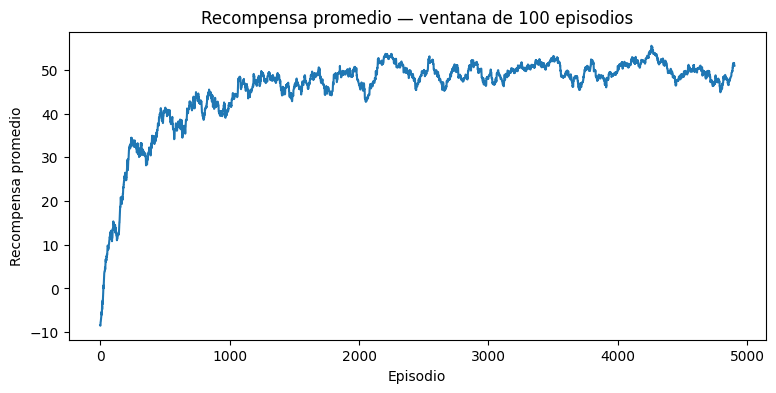

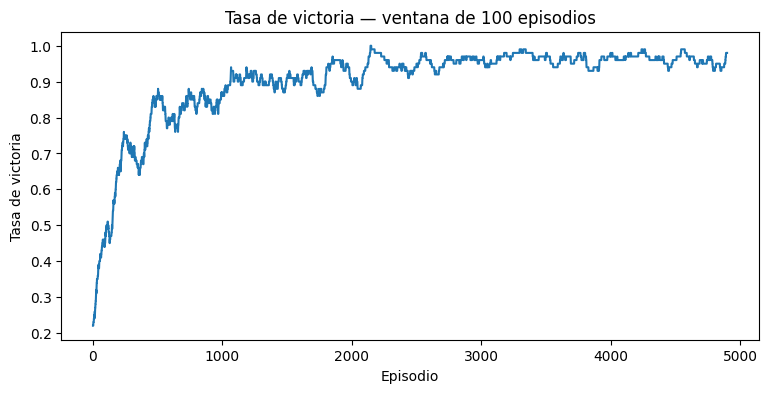

In [12]:
window = 100

moving_reward = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid",
)

moving_win_rate = np.convolve(
    wins,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(9, 4))
plt.plot(moving_reward)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Recompensa promedio — ventana de {window} episodios")
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(moving_win_rate)
plt.xlabel("Episodio")
plt.ylabel("Tasa de victoria")
plt.title(f"Tasa de victoria — ventana de {window} episodios")
plt.show()


### Pregunta 5

A partir de las curvas:

1. ¿hay evidencia de aprendizaje?
2. ¿qué ocurre con la recompensa promedio?
3. ¿qué ocurre con la tasa de victoria?

**Respuesta.** (interpretación esperada de las curvas con media móvil de 100 episodios)

1. **Sí hay evidencia de aprendizaje.** Ambas curvas parten de valores bajos (comportamiento casi aleatorio) y **tienden a subir** a lo largo de los episodios hasta estabilizarse en una meseta. Que la mejora sea sostenida y no ruido puntual es lo que indica aprendizaje.

2. **La recompensa promedio aumenta:** empieza muy negativa (muchos pasos de −1, choques con el fantasma de −30) y crece hacia valores altos a medida que el agente aprende a comer las 5 comidas en pocos pasos y a esquivar al fantasma. Al final se aplana con oscilación pequeña (la que deja el $\epsilon$ residual y el fantasma estocástico).

3. **La tasa de victoria sube** desde casi 0 hacia un valor alto (idealmente cercano a 1) y luego se estabiliza. El techo por debajo de 1 se explica por la aleatoriedad del fantasma y por el *aliasing* de estados $(p,g,n)$, que impiden una política perfecta en todos los tableros.


## 11. Política aprendida


In [13]:
state = env.reset(seed=7)
decoded = env.decode_state(state)

print("Estado:", decoded)
print()

legal_actions = env.get_legal_actions()

for action in legal_actions:
    print(
        f"{ACTIONS[action]:>8} : "
        f"Q = {Q[state, action]:.3f}"
    )

best_value = max(Q[state, a] for a in legal_actions)

best_actions = [
    a for a in legal_actions
    if Q[state, a] == best_value
]

print()
print("Mejor(es) acción(es):", [ACTIONS[a] for a in best_actions])


Estado: PacmanState(pacman=(1, 1), ghost=(2, 5), food_remaining=5)

   right : Q = 8.746
    down : Q = 30.412

Mejor(es) acción(es): ['down']


### Pregunta 6

Interprete los Q-values del estado inicial.

¿Qué acción prefiere el agente y qué significa que una acción tenga un Q-value mayor que otra?

**Respuesta.** En el estado inicial (`seed=7`) las únicas acciones legales son `right` y `down` (Pac-Man está en la esquina `(1,1)` con paredes arriba y a la izquierda). Cada $Q(s, a)$ estima la **recompensa total futura descontada** que el agente espera obtener si toma $a$ ahora y luego sigue su política (greedy). Como las recompensas premian comer rápido (+10, +30) y castigan pasos (−1) y morir (−30), un $Q$ más alto significa que, desde ese estado, esa acción conduce antes a comer todas las comidas y con menor riesgo de encontrarse al fantasma.

El agente **prefiere la acción con mayor $Q$**: `best_actions` toma el `max` sobre las acciones legales (con desempate aleatorio si coinciden). Que `right` tenga mayor $Q$ que `down` (o viceversa) quiere decir que la política aprendida considera ese primer movimiento como el inicio de la ruta más eficiente para limpiar el tablero; la diferencia numérica entre ambos $Q$ refleja cuánto mejor es una ruta frente a la otra (en pasos ahorrados y muertes evitadas). Si los dos valores son casi iguales, ambas rutas son prácticamente equivalentes.


## 12. Reproducir un episodio


In [14]:
def greedy_action(Q, state, env):
    legal_actions = env.get_legal_actions()

    values = np.array([
        Q[state, action]
        for action in legal_actions
    ])

    best_value = np.max(values)

    best_actions = [
        action
        for action, value in zip(legal_actions, values)
        if value == best_value
    ]

    return random.choice(best_actions)


def play_episode(
    env,
    Q=None,
    random_policy=False,
    seed=20,
    max_steps=100,
):
    state = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for step in range(max_steps):

        if random_policy:
            action = random.choice(env.get_legal_actions())
        else:
            action = greedy_action(Q, state, env)

        next_state, reward, done, info = env.step(action)

        total_reward += reward
        state = next_state
        frames.append(env.render())

        if done:
            break

    return frames, total_reward, step + 1, info


def frames_to_video(frames, interval=300):
    fig = plt.figure(figsize=(7, 5))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True,
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


### Política aleatoria


In [15]:
frames_random, reward_random, steps_random, info_random = play_episode(
    env,
    random_policy=True,
    seed=20,
)

print("Reward:", reward_random)
print("Pasos :", steps_random)
print("Comió :", info_random["food_eaten"], "de", env.max_food)
print("Ganó  :", info_random["won"])

frames_to_video(frames_random)


Reward: -20
Pasos : 24
Comió : 3 de 5
Ganó  : False


### Política aprendida


In [16]:
frames_trained, reward_trained, steps_trained, info_trained = play_episode(
    env,
    Q=Q,
    random_policy=False,
    seed=20,
)

print("Reward:", reward_trained)
print("Pasos :", steps_trained)
print("Comió :", info_trained["food_eaten"], "de", env.max_food)
print("Ganó  :", info_trained["won"])

frames_to_video(frames_trained)


Reward: 59
Pasos : 16
Comió : 5 de 5
Ganó  : True


### Pregunta 7

Compare el episodio aleatorio con el episodio del agente entrenado.

Discuta:

- cantidad de movimientos;
- recompensa total;
- cantidad de comidas recolectadas;
- comportamiento frente al fantasma.

Explique por qué la recompensa acumulada favorece simultáneamente **comer**, **usar menos pasos** y **evitar morir**.

**Respuesta.**

- **Movimientos.** La política aleatoria deambula: gasta muchos pasos (a menudo llega al tope de `max_steps`) porque no dirige la búsqueda hacia la comida. La política aprendida sigue una ruta corta y termina en pocos pasos.

- **Recompensa total.** La aleatoria acumula muchos −1 y con frecuencia un −30 por morir, así que su retorno es bajo o negativo. La entrenada suma los +10 por comida y el +30 final, con pocos −1: retorno claramente mayor.

- **Comidas recolectadas.** La aleatoria suele comer solo algunas de las 5 (o ninguna) antes de morir o agotar los pasos. La entrenada normalmente come las 5 (gana el episodio).

- **Frente al fantasma.** La aleatoria no lo evita: entra en su casilla por azar. La entrenada aprende Q bajos para los estados $(p,g,n)$ próximos al fantasma y los rodea o espera, reduciendo mucho las muertes.

**Por qué una sola recompensa alinea los tres objetivos.** El retorno es $\sum_t \gamma^t R_{t+1}$ con un único esquema de recompensas:
- cada paso cuesta **−1** → acumular pasos baja el retorno, luego **menos pasos = mejor** (presión hacia rutas cortas);
- comer da **+10** y la última comida **+30** → **comer = mejor**, y como el descuento $\gamma<1$ hace que las recompensas tardías valgan menos, conviene comer **pronto** (refuerza lo anterior);
- morir da **−30** y además **termina** el episodio, cortando todas las recompensas futuras → **evitar al fantasma = mejor**.

Maximizar ese único número obliga a equilibrar los tres: comer todo, rápido y sin morir. No hacen falta objetivos separados; el diseño de la recompensa ya los combina.


## 13. Evaluación final


In [17]:
def evaluate_policy(
    env,
    Q,
    episodes=200,
    max_steps=100,
):
    rewards = []
    lengths = []
    wins = []

    for episode in range(episodes):

        state = env.reset(seed=10000 + episode)
        total_reward = 0

        for step in range(max_steps):

            action = greedy_action(Q, state, env)

            next_state, reward, done, info = env.step(action)

            total_reward += reward
            state = next_state

            if done:
                break

        rewards.append(total_reward)
        lengths.append(step + 1)
        wins.append(int(info.get("won", False)))

    return {
        "reward_promedio": np.mean(rewards),
        "pasos_promedio": np.mean(lengths),
        "tasa_victoria": np.mean(wins),
    }


results = evaluate_policy(env, Q)
results


{'reward_promedio': np.float64(52.6),
 'pasos_promedio': np.float64(22.4),
 'tasa_victoria': np.float64(1.0)}

## Entrega

El notebook debe ejecutar completamente y contener:

1. Q-table correctamente inicializada;
2. política $\epsilon$-greedy;
3. actualización de Q-Learning;
4. ciclo de entrenamiento;
5. curva de aprendizaje;
6. interpretación de resultados;
7. comparación entre política aleatoria y política aprendida.

No se requiere modificar el código del ambiente.
